# Задание 5. Исследовательский анализ SMS-данных (EDA)

**Проект:** SMS Guard · **Автор:** Омаров М.Е., SIS-2304

**Данные:** `data/processed/sms_clean.csv` — набор UCI SMS Spam Collection после очистки (задание 4):
5135 сообщений, дубликаты удалены.

**Условие корректности.** Анализ выполняется на всём очищенном наборе **до** разбиения и обучения.
По его результатам не подбираются никакие параметры модели и порог — он только описывает данные
и даёт гипотезы для признаков (задание 6). Подбор параметров будет выполняться только на обучающей
и валидационной выборках.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=matplotlib.MatplotlibDeprecationWarning)
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 80)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from ml.preprocessing import STOP_WORDS  # noqa: E402

FIG_DIR = PROJECT_ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
COLORS = {0: "#2e7d32", 1: "#c62828"}
NAMES = {0: "Безопасные (ham)", 1: "Мошеннические (spam)"}

df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "sms_clean.csv", keep_default_na=False)
print(df.shape)
df.head()

(5135, 4)


,id,text_raw,text_clean,label
0,1,"Go until jurong point, crazy.. Available only in bugis n great world la e bu...","go until jurong point, crazy.. available only in bugis n great world la e bu...",0
1,2,Ok lar... Joking wif u oni...,ok lar... joking wif u oni...,0
2,3,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA ...,free entry in <num> a wkly comp to win fa cup final tkts 21st may <num> . te...,1
3,4,U dun say so early hor... U c already then say...,u dun say so early hor... u c already then say...,0
4,5,"Nah I don't think he goes to usf, he lives around here though","nah i don't think he goes to usf, he lives around here though",0


## 1. Распределение классов

Соотношение ham : spam = 7.30 : 1


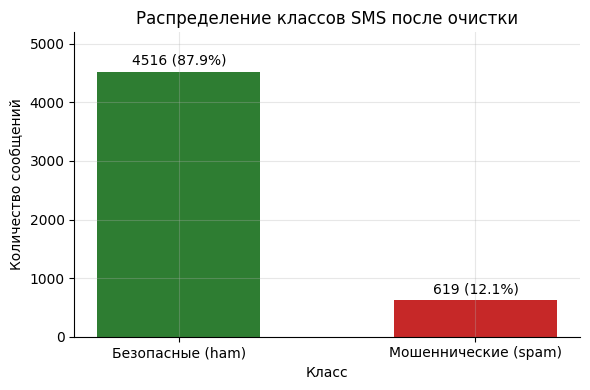

In [2]:
counts = df["label"].value_counts().sort_index()
shares = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar([NAMES[i] for i in counts.index], counts.values,
              color=[COLORS[i] for i in counts.index], width=0.55)
ax.bar_label(bars, labels=[f"{c} ({s:.1f}%)" for c, s in zip(counts, shares)], padding=3)
ax.set_title("Распределение классов SMS после очистки")
ax.set_xlabel("Класс")
ax.set_ylabel("Количество сообщений")
ax.set_ylim(0, counts.max() * 1.15)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_class_distribution.png", dpi=150)
print(f"Соотношение ham : spam = {counts[0] / counts[1]:.2f} : 1")

## 2. Длина сообщений по классам

Длина считается по исходному тексту (`text_raw`): в символах и в словах (разделитель — пробел).

In [3]:
df["len_chars"] = df["text_raw"].str.len()
df["len_words"] = df["text_raw"].str.split().str.len()

length_stats = df.groupby("label")[["len_chars", "len_words"]].agg(["mean", "median", "std", "min", "max"]).round(1)
length_stats.index = [NAMES[i] for i in length_stats.index]
length_stats

len_chars                       len_words                      
                          mean median   std min  max      mean median   std min  max
Безопасные (ham)          70.9   53.0  56.6   2  910      14.2   11.0  11.2   1  171
Мошеннические (spam)     137.5  148.0  30.1  13  223      23.7   25.0   6.0   2   35

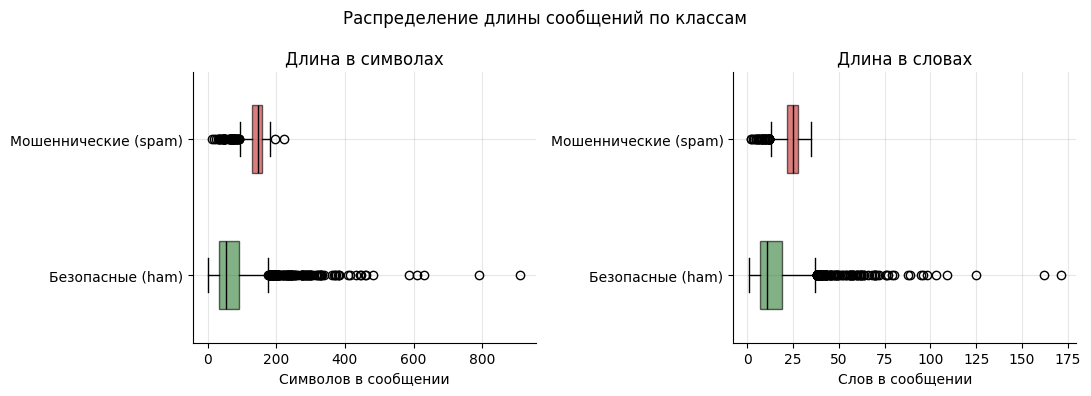

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, title, xlabel in [
    (axes[0], "len_chars", "Длина в символах", "Символов в сообщении"),
    (axes[1], "len_words", "Длина в словах", "Слов в сообщении"),
]:
    data = [df.loc[df["label"] == k, col] for k in (0, 1)]
    bp = ax.boxplot(data, vert=False, patch_artist=True, widths=0.5,
                    medianprops={"color": "black"})
    for patch, k in zip(bp["boxes"], (0, 1)):
        patch.set_facecolor(COLORS[k])
        patch.set_alpha(0.6)
    ax.set_yticks([1, 2], [NAMES[0], NAMES[1]])
    ax.set_title(title)
    ax.set_xlabel(xlabel)
fig.suptitle("Распределение длины сообщений по классам")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_length_boxplot.png", dpi=150)

Доля сообщений длиной 120–160 символов, %: {0: 12.3, 1: 72.7}


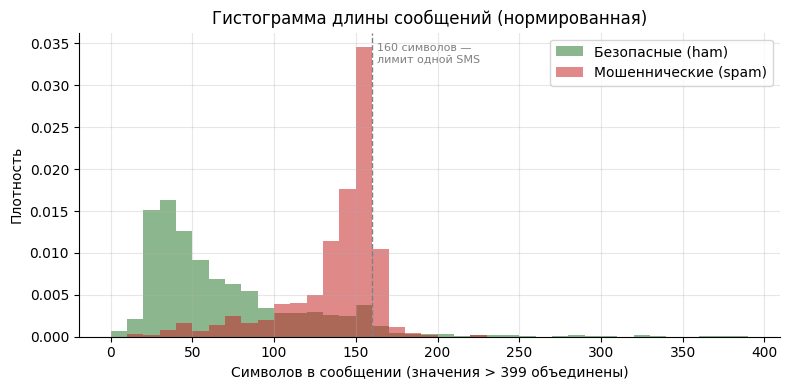

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(0, 400, 10)
for k in (0, 1):
    ax.hist(df.loc[df["label"] == k, "len_chars"].clip(upper=399), bins=bins, density=True,
            alpha=0.55, color=COLORS[k], label=NAMES[k])
ax.axvline(160, color="grey", linestyle="--", linewidth=1)
ax.text(163, ax.get_ylim()[1] * 0.9, "160 символов —\nлимит одной SMS", fontsize=8, color="grey")
ax.set_title("Гистограмма длины сообщений (нормированная)")
ax.set_xlabel("Символов в сообщении (значения > 399 объединены)")
ax.set_ylabel("Плотность")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "05_length_hist.png", dpi=150)

share_140_160 = df.groupby("label")["len_chars"].apply(lambda s: ((s >= 120) & (s <= 160)).mean() * 100).round(1)
print("Доля сообщений длиной 120–160 символов, %:", share_140_160.to_dict())

## 3. Топ-20 слов и биграмм по классам (без стоп-слов)

Используется `text_clean`; спецтокены (`<url>`, `<num>` …) и знаки `!`, `?` исключены —
их доля анализируется отдельно в разделе 4. Стоп-слова: английский список scikit-learn +
русский и казахский списки из `ml/preprocessing.py`.

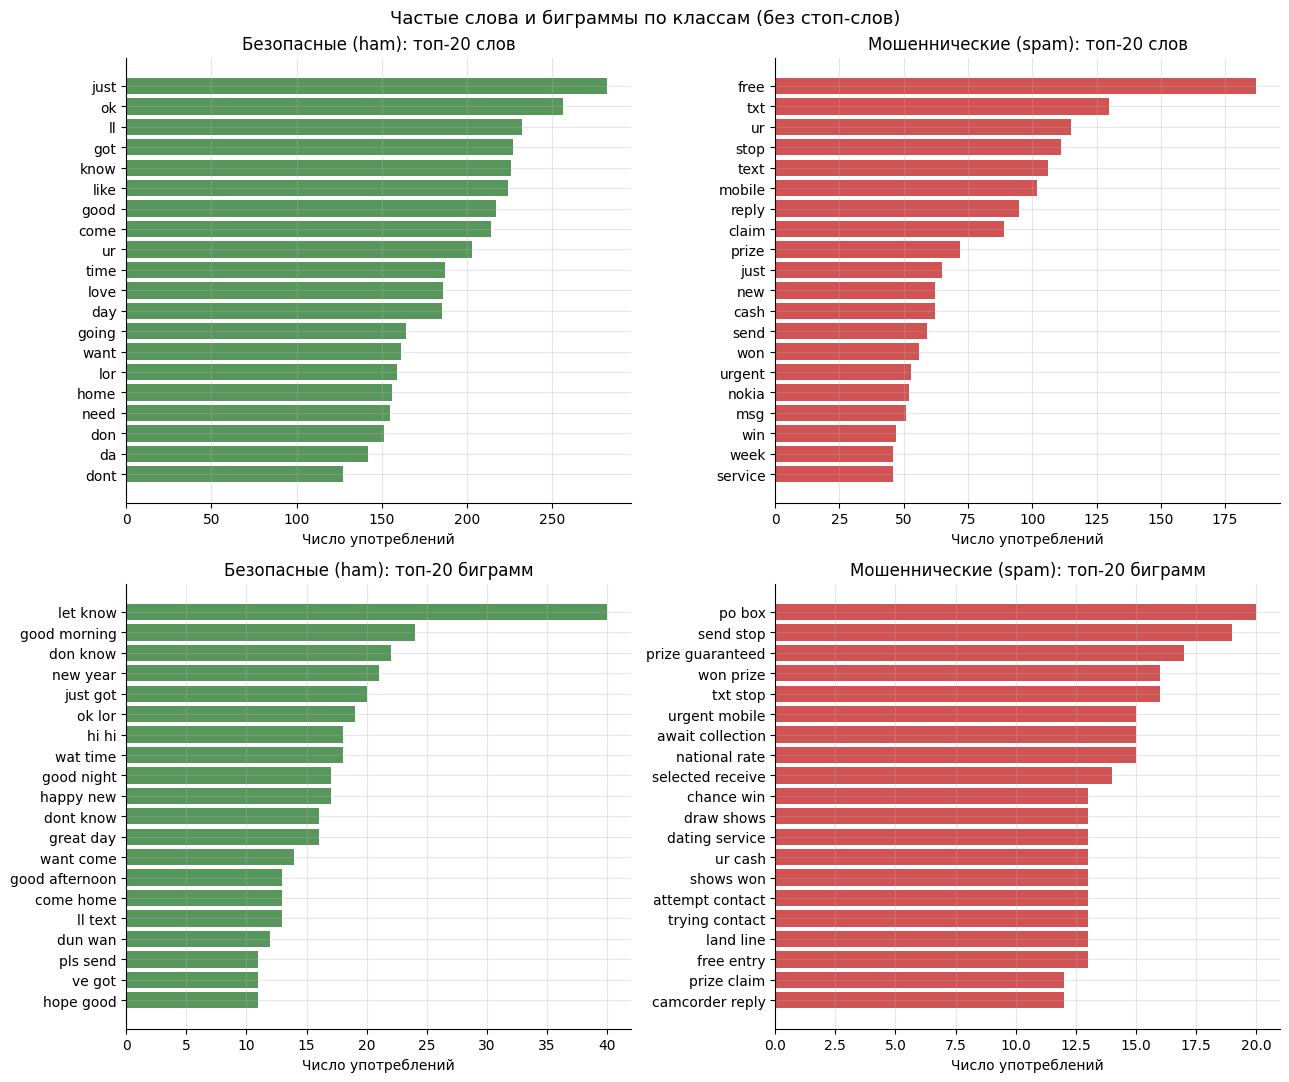

In [6]:
words_only = df["text_clean"].str.replace(r"<\w+>|[!?]", " ", regex=True)


def top_ngrams(texts, ngram, n=20):
    vec = CountVectorizer(ngram_range=(ngram, ngram), stop_words=list(STOP_WORDS),
                          token_pattern=r"(?u)\b[^\W\d_][^\W\d_]+\b")
    m = vec.fit_transform(texts)
    freq = np.asarray(m.sum(axis=0)).ravel()
    order = freq.argsort()[::-1][:n]
    return pd.Series(freq[order], index=vec.get_feature_names_out()[order])


tops = {(k, g): top_ngrams(words_only[df["label"] == k], g) for k in (0, 1) for g in (1, 2)}

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for (k, g), ax in zip([(0, 1), (1, 1), (0, 2), (1, 2)], axes.ravel()):
    s = tops[(k, g)][::-1]
    ax.barh(s.index, s.values, color=COLORS[k], alpha=0.8)
    ax.set_title(f"{NAMES[k]}: топ-20 {'слов' if g == 1 else 'биграмм'}")
    ax.set_xlabel("Число употреблений")
fig.suptitle("Частые слова и биграммы по классам (без стоп-слов)", fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_top_words_bigrams.png", dpi=150)

In [7]:
pd.concat({f"{NAMES[k]} — {'слова' if g == 1 else 'биграммы'}":
           tops[(k, g)].reset_index().apply(lambda r: f"{r.iloc[0]} ({r.iloc[1]})", axis=1)
           for k in (0, 1) for g in (1, 2)}, axis=1)

,Безопасные (ham) — слова,Безопасные (ham) — биграммы,Мошеннические (spam) — слова,Мошеннические (spam) — биграммы
0,just (282),let know (40),free (187),po box (20)
1,ok (256),good morning (24),txt (130),send stop (19)
2,ll (232),don know (22),ur (115),prize guaranteed (17)
3,got (227),new year (21),stop (111),won prize (16)
4,know (226),just got (20),text (106),txt stop (16)
5,like (224),ok lor (19),mobile (102),urgent mobile (15)
6,good (217),hi hi (18),reply (95),await collection (15)
7,come (214),wat time (18),claim (89),national rate (15)
8,ur (203),good night (17),prize (72),selected receive (14)
9,time (187),happy new (17),just (65),chance win (13)


## 4. Спецтокены и знаки давления по классам

Доля сообщений, в которых встречается хотя бы один `<url>`, `<phone>`, `<money>`, `<num>`, `!`.

In [8]:
markers = {"<url>": "<url>", "<phone>": "<phone>", "<money>": "<money>", "<num>": "<num>", "!": "!"}
marker_share = pd.DataFrame({
    NAMES[k]: {m: df.loc[df["label"] == k, "text_clean"].str.contains(pat, regex=False).mean() * 100
               for m, pat in markers.items()}
    for k in (0, 1)
}).round(1)
marker_share["Отношение spam / ham"] = (marker_share[NAMES[1]] / marker_share[NAMES[0]].replace(0, np.nan)).round(1)
marker_share

,Безопасные (ham),Мошеннические (spam),Отношение spam / ham
<url>,0.3,18.6,62.0
<phone>,0.1,54.3,543.0
<money>,0.3,53.8,179.3
<num>,16.4,73.8,4.5
!,11.7,47.2,4.0


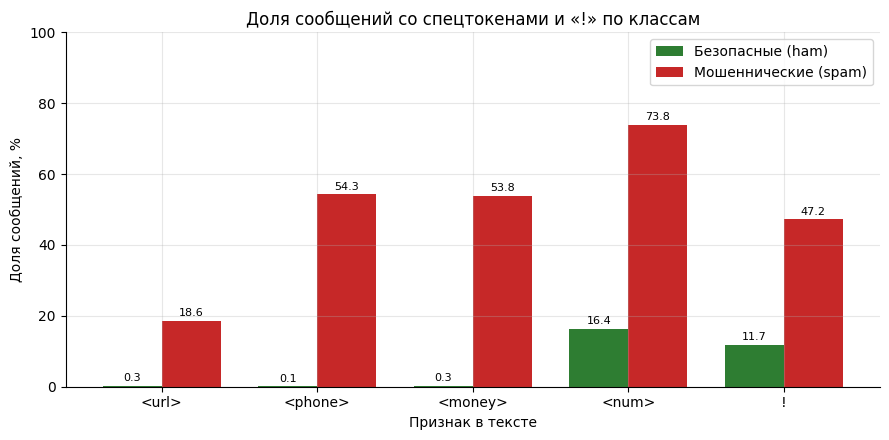

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(markers))
w = 0.38
for i, k in enumerate((0, 1)):
    vals = marker_share[NAMES[k]].values
    b = ax.bar(x + (i - 0.5) * w, vals, w, color=COLORS[k], label=NAMES[k])
    ax.bar_label(b, labels=[f"{v:.1f}" for v in vals], padding=2, fontsize=8)
ax.set_xticks(x, list(markers))
ax.set_title("Доля сообщений со спецтокенами и «!» по классам")
ax.set_xlabel("Признак в тексте")
ax.set_ylabel("Доля сообщений, %")
ax.set_ylim(0, 100)
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "05_markers_by_class.png", dpi=150)

## 5. Дополнительно: заглавные буквы и восклицательные знаки

In [10]:
df["upper_ratio"] = df["text_raw"].map(lambda t: sum(c.isupper() for c in t) / max(1, sum(c.isalpha() for c in t)))
df["n_exclaim"] = df["text_raw"].str.count("!")
df["has_free"] = df["text_clean"].str.contains(r"\bfree\b", regex=True)
df["has_any_marker"] = df["text_clean"].str.contains(r"<url>|<phone>|<money>", regex=True)

extra = df.groupby("label").agg(
    upper_ratio_mean=("upper_ratio", "mean"),
    exclaim_mean=("n_exclaim", "mean"),
    free_share=("has_free", "mean"),
    any_marker_share=("has_any_marker", "mean"),
)
extra[["upper_ratio_mean", "free_share", "any_marker_share"]] *= 100
extra.columns = ["Доля заглавных букв, %", "Среднее число «!»", "Доля со словом free, %",
                 "Доля с <url>/<phone>/<money>, %"]
extra.index = [NAMES[i] for i in extra.index]
extra.round(2)

,"Доля заглавных букв, %",Среднее число «!»,"Доля со словом free, %","Доля с <url>/<phone>/<money>, %"
Безопасные (ham),7.67,0.18,1.22,0.66
Мошеннические (spam),16.63,0.70,23.10,83.20


In [11]:
spam_no_marker = df[(df["label"] == 1) & ~df["has_any_marker"]]
ham_with_marker = df[(df["label"] == 0) & df["has_any_marker"]]
print(f"Spam без <url>/<phone>/<money>: {len(spam_no_marker)} из {(df['label'] == 1).sum()}")
for t in spam_no_marker["text_raw"].head(5):
    print("  spam:", t[:120])
print(f"\nHam с <url>/<phone>/<money>: {len(ham_with_marker)} из {(df['label'] == 0).sum()}")
for t in ham_with_marker["text_raw"].head(5):
    print("  ham: ", t[:120])

Spam без <url>/<phone>/<money>: 104 из 619
  spam: England v Macedonia - dont miss the goals/team news. Txt ur national team to 87077 eg ENGLAND to 87077 Try:WALES, SCOTLA
  spam: SMS. ac Sptv: The New Jersey Devils and the Detroit Red Wings play Ice Hockey. Correct or Incorrect? End? Reply END SPTV
  spam: Did you hear about the new "Divorce Barbie"? It comes with all of Ken's stuff!
  spam: Your free ringtone is waiting to be collected. Simply text the password "MIX" to 85069 to verify. Get Usher and Britney.
  spam: You'll not rcv any more msgs from the chat svc. For FREE Hardcore services text GO to: 69988 If u get nothing u must Age

Ham с <url>/<phone>/<money>: 30 из 4516
  ham:  Do you know what Mallika Sherawat did yesterday? Find out now @  &lt;URL&gt;
  ham:  Your gonna have to pick up a $1 burger for yourself on your way home. I can't even move. Pain is killing me.
  ham:  MY NO. IN LUTON 0125698789 RING ME IF UR AROUND! H*
  ham:  Good evening Sir, Al Salam Wahleykkum.shari

## 6. Выводы

Все числа ниже получены в ячейках выше.

1. **Сильный дисбаланс классов.** После очистки 4516 безопасных (87,9%) и 619 мошеннических (12,1%) сообщений, соотношение 7,3 : 1. Модель, которая на всё отвечает «ham», получит Accuracy 87,9% и не найдёт ни одного мошенничества. **Как учитываем:** стратифицированное разбиение 70/15/15 (задание 6), `class_weight='balanced'` в моделях, основные метрики — Precision, Recall, F1/F2 и PR-AUC для класса spam, а не Accuracy.
2. **Мошеннические SMS почти вдвое длиннее.** Средняя длина spam — 137,5 символа против 70,9 у ham (медиана 148 против 53), в словах — 23,7 против 14,2. 72,7% spam имеют длину 120–160 символов (у ham — 12,3%): рассылки заполняют одну SMS почти до лимита в 160 символов. **Гипотеза:** длина сообщения — полезный ручной признак.
3. **Длина spam однородна, ham — нет.** Стандартное отклонение длины у spam 30,1 символа, у ham — 56,6; самое длинное spam — 223 символа, ham — 910. Все 57 сообщений длиннее 250 символов — ham; из 1549 сообщений короче 40 символов spam только 8.
4. **Контакты и суммы — самый сильный сигнал.** Телефон (`<phone>`) есть в 54,3% spam и в 0,1% ham, сумма с валютой (`<money>`) — 53,8% против 0,3%, ссылка (`<url>`) — 18,6% против 0,3%. Хотя бы один из трёх токенов есть в 83,2% spam и лишь в 0,66% ham. **Гипотеза:** признаки «есть `<url>`», «есть `<money>`» сильно разделяют классы. При этом 104 spam (16,8%) не содержат ни одного из них — значит, без анализа слов не обойтись.
5. **Признаки давления.** «!» встречается в 47,2% spam и 11,7% ham (в 4 раза чаще), в среднем 0,70 против 0,18 знака на сообщение. Доля заглавных букв в spam 16,6% против 7,7% (`URGENT`, `WINNER`, `FREE`). **Гипотеза:** число «!» и доля заглавных — полезные ручные признаки; поэтому доля заглавных считается по исходному тексту (`text_raw`), до приведения к нижнему регистру.
6. **Лексика spam — выигрыш и призыв к действию.** Топ-слова spam: free (187), txt (130), stop (111), text (106), mobile (102), reply (95), claim (89), prize (72), cash (62), won (56), urgent (53). Слово free есть в 23,1% spam и 1,2% ham. Биграммы spam: prize guaranteed, won prize, urgent mobile, chance win, ur awarded — это группы «выигрыш/приз» и «срочность» из словаря правил. Лексика ham — разговорная: just, ok, know, love, home, good morning.
7. **Сленг и сокращения в обоих классах.** ur (spam — 115, ham — 203), txt, lor, da, dont, wat: короткие и намеренно искажённые формы. **Гипотеза:** символьные N-граммы (`char_wb`, 3–5) устойчивее к таким формам и искажениям (`fr33`, `b@nk`), чем словарь слов.
8. **Ограничение набора.** Ссылки есть только в 18,6% spam: это спам до 2012 года (короткие номера, призы, подписки), а современный смишинг (поддельный банк, доставка) почти всегда содержит ссылку. Поэтому ссылки анализируются отдельной URL-моделью (задания 9–11), а на русском и казахском текстовая модель проверяется отдельно (задание 8).

**Итог для задания 6:** TF-IDF по словам и биграммам + символьные N-граммы + ручные признаки: длина, доля заглавных, число «!», наличие `<url>`, `<money>`, `<phone>`, число сработавших групп словаря социальной инженерии.